In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def analyser_progression(historique, id_sportif):

    df = historique[
        historique["id_sportif"] == id_sportif
    ].copy()

    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    if len(df) < 2:
        print("Pas assez de séances pour analyser la progression.")
        return None

   

    nb_seances = len(df)
    distance_totale = df["distance_km"].sum()
    duree_totale_h = df["duree_secondes"].sum() / 3600

    

    premiere = df.iloc[0]
    derniere = df.iloc[-1]

    def evolution_pourcentage(debut, fin):
        if debut == 0:
            return None
        return (fin - debut) / debut * 100

    evolution_vitesse = evolution_pourcentage(
        premiere["vitesse_moyenne"],
        derniere["vitesse_moyenne"]
    )

    evolution_fc = evolution_pourcentage(
        premiere["fc_moyenne"],
        derniere["fc_moyenne"]
    )

    evolution_duree = evolution_pourcentage(
        premiere["duree_secondes"],
        derniere["duree_secondes"]
    )

    

    meilleure_vitesse = df["vitesse_moyenne"].max()
    meilleur_temps = df["duree_secondes"].min()

   

    df["vitesse_mobile"] = (
        df["vitesse_moyenne"]
        .rolling(window=3, min_periods=1)
        .mean()
    )

    df["fc_mobile"] = (
        df["fc_moyenne"]
        .rolling(window=3, min_periods=1)
        .mean()
    )

   

    print("===== ANALYSE HISTORIQUE DATAFIT =====")

    print("Nombre de séances :", nb_seances)
    print("Distance totale :", round(distance_totale, 2), "km")
    print("Durée totale :", round(duree_totale_h, 2), "heures")

    print("\n===== ÉVOLUTION =====")

    print("Évolution vitesse :", round(evolution_vitesse, 2), "%")
    print("Évolution FC :", round(evolution_fc, 2), "%")
    print("Évolution durée :", round(evolution_duree, 2), "%")

    print("\n===== RECORDS =====")

    print("Meilleure vitesse :", meilleure_vitesse, "km/h")
    print("Meilleur temps :", round(meilleur_temps / 60, 2), "minutes")

    

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Vitesse moyenne
    axes[0, 0].plot(
        df["date"], df["vitesse_moyenne"],
        marker="o", label="Vitesse moyenne"
    )

    axes[0, 0].plot(
        df["date"], df["vitesse_mobile"],
        linestyle="--", label="Moyenne mobile (3 séances)"
    )

    axes[0, 0].set_title("Évolution de la vitesse")
    axes[0, 0].set_ylabel("km/h")
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    
    axes[0, 1].plot(
        df["date"], df["fc_moyenne"],
        marker="o", label="FC moyenne"
    )

    axes[0, 1].plot(
        df["date"], df["fc_mobile"],
        linestyle="--", label="Moyenne mobile (3 séances)"
    )

    axes[0, 1].set_title("Évolution de la fréquence cardiaque")
    axes[0, 1].set_ylabel("bpm")
    axes[0, 1].legend()
    axes[0, 1].grid(True)

   
    axes[1, 0].plot(
        df["date"], df["duree_secondes"] / 60,
        marker="o"
    )

    axes[1, 0].set_title("Évolution du temps sur 5 km")
    axes[1, 0].set_ylabel("Minutes")
    axes[1, 0].grid(True)

  
    axes[1, 1].plot(
        df["date"], df["regularite"],
        marker="o"
    )

    axes[1, 1].set_title("Évolution de la régularité")
    axes[1, 1].set_ylabel("Coefficient de variation (%)")
    axes[1, 1].grid(True)

    for ax in axes.flat:
        ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

   

    resultats = {
        "nombre_seances": nb_seances,
        "distance_totale_km": round(distance_totale, 2),
        "duree_totale_h": round(duree_totale_h, 2),
        "evolution_vitesse_pct": round(evolution_vitesse, 2),
        "evolution_fc_pct": round(evolution_fc, 2),
        "evolution_duree_pct": round(evolution_duree, 2),
        "meilleure_vitesse": float(meilleure_vitesse),
        "meilleur_temps_secondes": int(meilleur_temps)
    }

    return resultats

In [9]:
import pandas as pd

historique = pd.read_csv("historique_datafit_exemple.csv")

display(historique.head())
print("Nombre de séances :", len(historique))
print("Colonnes :", historique.columns.tolist())
print("Sportifs :", historique["id_sportif"].unique())

,id_sportif,id_seance,date,distance_km,duree_secondes,vitesse_moyenne,vitesse_max,fc_moyenne,fc_max,regularite,correlation_fc_vitesse
0,1,1,2026-05-04,5.0,1954,9.21,10.84,157.68,167.61,8.10,0.609
1,1,2,2026-05-07,5.0,1921,9.37,10.37,150.08,168.36,7.98,0.379
2,1,3,2026-05-10,5.0,1925,9.35,10.54,156.49,173.31,5.91,0.759
3,1,4,2026-05-13,5.0,1965,9.16,10.79,156.58,166.06,7.73,0.535
4,1,5,2026-05-16,5.0,1842,9.77,10.86,153.76,172.54,7.33,0.408


Nombre de séances : 24
Colonnes : ['id_sportif', 'id_seance', 'date', 'distance_km', 'duree_secondes', 'vitesse_moyenne', 'vitesse_max', 'fc_moyenne', 'fc_max', 'regularite', 'correlation_fc_vitesse']
Sportifs : [1]


===== ANALYSE HISTORIQUE DATAFIT =====
Nombre de séances : 24
Distance totale : 120.0 km
Durée totale : 11.97 heures

===== ÉVOLUTION =====
Évolution vitesse : 19.22 %
Évolution FC : -4.26 %
Évolution durée : -16.12 %

===== RECORDS =====
Meilleure vitesse : 10.98 km/h
Meilleur temps : 27.32 minutes


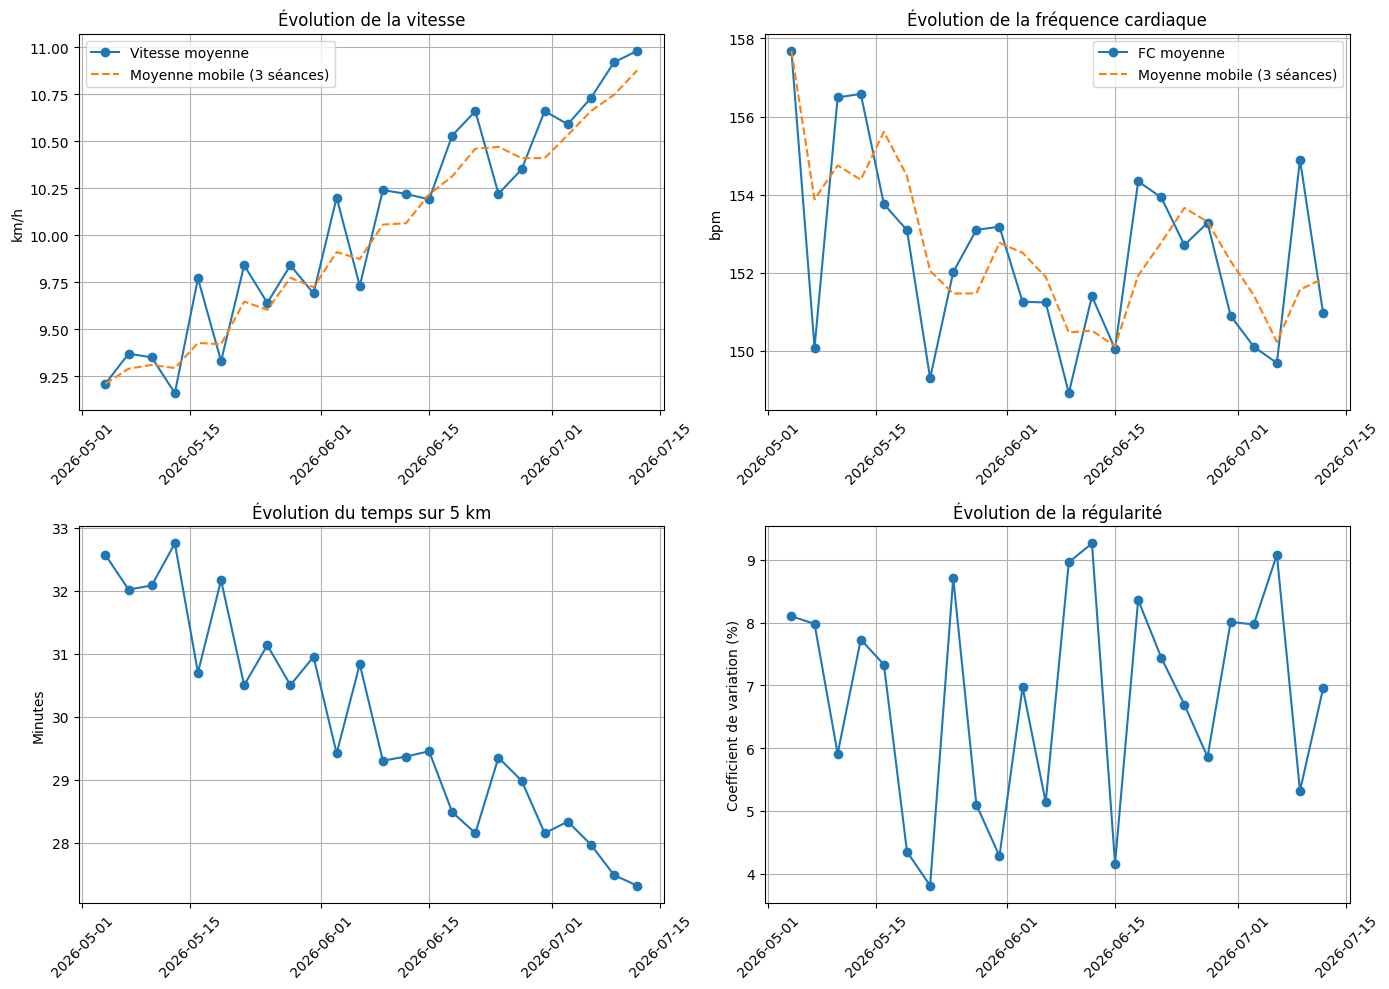

{'nombre_seances': 24, 'distance_totale_km': np.float64(120.0), 'duree_totale_h': np.float64(11.97), 'evolution_vitesse_pct': np.float64(19.22), 'evolution_fc_pct': np.float64(-4.26), 'evolution_duree_pct': np.float64(-16.12), 'meilleure_vitesse': 10.98, 'meilleur_temps_secondes': 1639}


In [10]:
resultats = analyser_progression(historique, id_sportif=1)

print(resultats)